<a href="https://colab.research.google.com/github/noorahmedbhatti007-byte/US-Airline-Flight-Delays-PySpark/blob/main/BAN_5600_Team_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Uncomment on Google Colab or any machine without PySpark:
!pip install -q pyspark

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F, types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.functions import vector_to_array

try:
    display  # available in Jupyter / Colab
except NameError:
    display = print

##Environment setup

In [2]:
os.environ["FLIGHTS_DATA_DIR"] = "/content"

DATA_DIR = os.getenv("FLIGHTS_DATA_DIR", "data")
OUTPUT_DIR = os.getenv("FLIGHTS_OUTPUT_DIR", "outputs")
FIG_DIR, TABLE_DIR = os.path.join(OUTPUT_DIR, "figures"), os.path.join(OUTPUT_DIR, "tables")

DELAY_THRESHOLD = 15
SEED = 42
MODEL_SAMPLE_FRACTION = float(os.getenv("MODEL_SAMPLE_FRACTION", "0.20"))
TUNING_SAMPLE_FRACTION = float(os.getenv("TUNING_SAMPLE_FRACTION", "0.30"))
MIN_FLIGHTS_AIRPORT = int(os.getenv("MIN_FLIGHTS_AIRPORT", "5000"))
MIN_FLIGHTS_ROUTE = int(os.getenv("MIN_FLIGHTS_ROUTE", "1000"))
TE_SMOOTHING = 50
DRIVER_MEMORY = os.getenv("SPARK_DRIVER_MEMORY", "8g")

for d in (FIG_DIR, TABLE_DIR):
    os.makedirs(d, exist_ok=True)

In [3]:
spark = (
    SparkSession.builder
    .appName("US-Flight-Delays-2015")
    .master("local[*]")                       # remove this line on Databricks / a real cluster
    .config("spark.driver.memory", DRIVER_MEMORY)
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Spark 4.0.4 | cores: 2


Chart Styles


In [4]:
ACCENT = "#2a78d6"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
RATE_LABEL = f"Share of flights arriving ≥{DELAY_THRESHOLD} min late"


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))
    plt.show()
    plt.close(fig)


def save_table(pdf, name):
    pdf.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"), index=False)
    return pdf


def _ref_line(ax, ref, vertical):
    if ref is None:
        return
    if vertical:
        ax.axvline(ref, color=MUTED, ls="--", lw=1)
        ax.annotate(f"overall {ref:.1%}", xy=(ref, 1), xycoords=("data", "axes fraction"),
                    xytext=(3, 2), textcoords="offset points", color=MUTED, fontsize=8, va="bottom")
    else:
        ax.axhline(ref, color=MUTED, ls="--", lw=1)
        ax.annotate(f"overall {ref:.1%}", xy=(1, ref), xycoords=("axes fraction", "data"),
                    xytext=(-2, 3), textcoords="offset points", color=MUTED, fontsize=8, ha="right")


def hbar(pdf, label_col, value_col, title, name, ref=None, xlabel=RATE_LABEL, pct=True):
    pdf = pdf.sort_values(value_col)
    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(pdf) + 1.3))
    ax.barh(pdf[label_col].astype(str), pdf[value_col], color=ACCENT, height=0.68)
    for y, v in enumerate(pdf[value_col]):
        ax.text(v, y, f" {v:.1%}" if pct else f" {v:,.1f}", va="center", fontsize=8, color=INK2)
    _ref_line(ax, ref, vertical=True)
    if pct:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.12)
    save_fig(fig, name)


def vbar(pdf, label_col, value_col, title, name, ref=None, xlabel=None, ylabel=RATE_LABEL):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.bar(pdf[label_col].astype(str), pdf[value_col], color=ACCENT, width=0.68)
    for x, v in enumerate(pdf[value_col]):
        ax.text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8, color=INK2)
    _ref_line(ax, ref, vertical=False)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel)
    save_fig(fig, name)


def line(pdf, x_col, value_col, title, name, ref=None, xlabel=None, ylabel=RATE_LABEL, xticklabels=None):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(pdf[x_col], pdf[value_col], color=ACCENT, lw=2, marker="o", ms=5)
    _ref_line(ax, ref, vertical=False)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    if xticklabels is not None:
        ax.set_xticks(list(pdf[x_col]))
        ax.set_xticklabels(xticklabels)
    ax.set_title(title)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel)
    save_fig(fig, name)

Selecting Variables

In [5]:
INT, DBL, STR = T.IntegerType(), T.DoubleType(), T.StringType()
flights_schema = T.StructType([T.StructField(n, t, True) for n, t in [
    ("YEAR", INT), ("MONTH", INT), ("DAY", INT), ("DAY_OF_WEEK", INT), ("AIRLINE", STR),
    ("FLIGHT_NUMBER", INT), ("TAIL_NUMBER", STR), ("ORIGIN_AIRPORT", STR), ("DESTINATION_AIRPORT", STR),
    ("SCHEDULED_DEPARTURE", INT), ("DEPARTURE_TIME", INT), ("DEPARTURE_DELAY", DBL), ("TAXI_OUT", DBL),
    ("WHEELS_OFF", INT), ("SCHEDULED_TIME", DBL), ("ELAPSED_TIME", DBL), ("AIR_TIME", DBL), ("DISTANCE", DBL),
    ("WHEELS_ON", INT), ("TAXI_IN", DBL), ("SCHEDULED_ARRIVAL", INT), ("ARRIVAL_TIME", INT),
    ("ARRIVAL_DELAY", DBL), ("DIVERTED", INT), ("CANCELLED", INT), ("CANCELLATION_REASON", STR),
    ("AIR_SYSTEM_DELAY", DBL), ("SECURITY_DELAY", DBL), ("AIRLINE_DELAY", DBL),
    ("LATE_AIRCRAFT_DELAY", DBL), ("WEATHER_DELAY", DBL),
]])

flights_raw = spark.read.csv(os.path.join(DATA_DIR, "flights.csv"), header=True, schema=flights_schema)
airlines = spark.read.csv(os.path.join(DATA_DIR, "airlines.csv"), header=True, inferSchema=True)
airports = spark.read.csv(os.path.join(DATA_DIR, "airports.csv"), header=True, inferSchema=True)

n_raw = flights_raw.count()
print(f"flights: {n_raw:,} rows × {len(flights_raw.columns)} columns")
print(f"airlines: {airlines.count()} rows | airports: {airports.count()} rows")
flights_raw.printSchema()

flights: 1,817,391 rows × 31 columns
airlines: 14 rows | airports: 322 rows
root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: integer (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: integer (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- WHEELS_ON: integer (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRI

##Handling Missing Values

In [6]:
INT, DBL, STR = T.IntegerType(), T.DoubleType(), T.StringType()
flights_schema = T.StructType([T.StructField(n, t, True) for n, t in [
    ("YEAR", INT), ("MONTH", INT), ("DAY", INT), ("DAY_OF_WEEK", INT), ("AIRLINE", STR),
    ("FLIGHT_NUMBER", INT), ("TAIL_NUMBER", STR), ("ORIGIN_AIRPORT", STR), ("DESTINATION_AIRPORT", STR),
    ("SCHEDULED_DEPARTURE", INT), ("DEPARTURE_TIME", INT), ("DEPARTURE_DELAY", DBL), ("TAXI_OUT", DBL),
    ("WHEELS_OFF", INT), ("SCHEDULED_TIME", DBL), ("ELAPSED_TIME", DBL), ("AIR_TIME", DBL), ("DISTANCE", DBL),
    ("WHEELS_ON", INT), ("TAXI_IN", DBL), ("SCHEDULED_ARRIVAL", INT), ("ARRIVAL_TIME", INT),
    ("ARRIVAL_DELAY", DBL), ("DIVERTED", INT), ("CANCELLED", INT), ("CANCELLATION_REASON", STR),
    ("AIR_SYSTEM_DELAY", DBL), ("SECURITY_DELAY", DBL), ("AIRLINE_DELAY", DBL),
    ("LATE_AIRCRAFT_DELAY", DBL), ("WEATHER_DELAY", DBL),
]])

flights_raw = spark.read.csv(os.path.join(DATA_DIR, "flights.csv"), header=True, schema=flights_schema)
airlines = spark.read.csv(os.path.join(DATA_DIR, "airlines.csv"), header=True, inferSchema=True)
airports = spark.read.csv(os.path.join(DATA_DIR, "airports.csv"), header=True, inferSchema=True)

n_raw = flights_raw.count()
print(f"flights: {n_raw:,} rows × {len(flights_raw.columns)} columns")
print(f"airlines: {airlines.count()} rows | airports: {airports.count()} rows")
flights_raw.printSchema()

flights: 1,817,391 rows × 31 columns
airlines: 14 rows | airports: 322 rows
root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: integer (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: integer (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- WHEELS_ON: integer (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRI

In [7]:
missing = (
    flights_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in flights_raw.columns])
    .toPandas().T.reset_index()
)
missing.columns = ["column", "missing"]
missing["missing_pct"] = (missing["missing"] / n_raw * 100).round(2)
display(save_table(missing.sort_values("missing", ascending=False), "02_missing_values"))

,column,missing,missing_pct
25,CANCELLATION_REASON,1769726,97.38
29,LATE_AIRCRAFT_DELAY,1457355,80.19
30,WEATHER_DELAY,1457355,80.19
28,AIRLINE_DELAY,1457355,80.19
26,AIR_SYSTEM_DELAY,1457355,80.19
27,SECURITY_DELAY,1457355,80.19
15,ELAPSED_TIME,52059,2.86
16,AIR_TIME,52059,2.86
22,ARRIVAL_DELAY,52059,2.86
18,WHEELS_ON,48686,2.68


- The five delay-cause columns are empty for 81.7% of rows because BTS only records cause minutes for flights that arrive **15+ minutes late** (confirmed in the data-quality check below).
- `CANCELLATION_REASON` is empty for 98.5% of rows because only cancelled flights have a reason.
- Actual-time columns (`DEPARTURE_TIME`, `ARRIVAL_DELAY`, etc.) are missing for 1.5–1.8% of rows, which are the cancelled and diverted flights that never completed a normal arrival.

Because `ARRIVAL_DELAY` is missing exactly for flights without a normal outcome, the target `DELAYED` is only defined for completed flights. Cancelled and diverted flights are described separately rather than forced into the on-time/delayed label.

###Flight outcomes, cancellations and descriptive statistics

Here we examine flight cancellations and diversions, identifies the most common cancellation reasons, and summarizes key flight characteristics, including departure and arrival delays, taxi times, scheduled flight duration, and distance.

In [8]:
CANCEL_REASONS = {"A": "Airline/Carrier", "B": "Weather", "C": "National Air System", "D": "Security"}
cancel_map = F.create_map(*[F.lit(x) for kv in CANCEL_REASONS.items() for x in kv])

outcomes = (flights_raw.groupBy("CANCELLED", "DIVERTED").count()
            .withColumn("share", F.col("count") / n_raw).orderBy("CANCELLED", "DIVERTED").toPandas())
display(outcomes)

(flights_raw.filter("CANCELLED = 1")
 .groupBy(cancel_map[F.col("CANCELLATION_REASON")].alias("cancellation_reason")).count()
 .orderBy(F.desc("count")).show())

DELAY_VARS = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "SCHEDULED_TIME", "DISTANCE"]
display(flights_raw.select(DELAY_VARS).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").toPandas())

,CANCELLED,DIVERTED,count,share
0,NaN,NaN,1,5.502393e-07
1,0.0,0.0,1765332,9.713551e-01
2,0.0,1.0,4393,2.417201e-03
3,1.0,0.0,47665,2.622716e-02


+-------------------+-----+
|cancellation_reason|count|
+-------------------+-----+
|            Weather|31007|
|    Airline/Carrier| 9741|
|National Air System| 6910|
|           Security|    7|
+-------------------+-----+



,summary,DEPARTURE_DELAY,ARRIVAL_DELAY,TAXI_OUT,TAXI_IN,SCHEDULED_TIME,DISTANCE
0,count,1771110,1765332,1770115,1768705,1817387,1817390
1,mean,9.885200241656362,5.719741102523491,16.24333955703443,7.395613174610803,140.68285621059246,809.7357342122494
2,stddev,37.26451838561685,39.792986893557554,9.362851513525491,5.8481191726518835,74.62369659977915,595.8707782951052
3,min,-68.0,-87.0,1.0,1.0,20.0,21.0
4,25%,-5.0,-12.0,11.0,4.0,85.0,370.0
5,50%,-1.0,-4.0,14.0,6.0,122.0,646.0
6,75%,9.0,10.0,19.0,9.0,173.0,1050.0
7,max,1988.0,1971.0,225.0,202.0,718.0,4983.0


**Flight outcomes and cancellations.** Of 5,819,079 scheduled flights:
- **98.2%** were completed,
- **1.54%** (89,884) were cancelled,
- **0.26%** (15,187) were diverted.

**Weather drives cancellations:** it accounts for **54%** of cancellations, compared with 28% for the airline/carrier, 18% for the National Air System and almost none for security (22 flights). This matters for interpreting the delay causes later. Severe weather tends to show up as **cancellations** rather than as delayed flights.

The descriptive statistics confirm the skew discussed above: departure delays average 9.4 minutes but the median is −2 (early). Taxi-out (median 14 min) is roughly twice taxi-in (median 6 min), which points to departure-side congestion at airports

###Data quality check

Here we categorise Delay-cause columns that is populated only when ARRIVAL_DELAY ≥ 15 and duplicates identified by date + airline + flight number + origin + scheduled departure.

In [9]:
iata_ok = F.col("ORIGIN_AIRPORT").rlike("^[A-Z]{3}$") & F.col("DESTINATION_AIRPORT").rlike("^[A-Z]{3}$")
display(flights_raw.groupBy("MONTH").agg(
    F.count("*").alias("flights"),
    F.sum((~iata_ok).cast("int")).alias("non_IATA_airport_codes")).orderBy("MONTH").toPandas())

CAUSE_COLS = {
    "AIRLINE_DELAY": "Air carrier",
    "LATE_AIRCRAFT_DELAY": "Late-arriving aircraft",
    "AIR_SYSTEM_DELAY": "National Aviation System",
    "WEATHER_DELAY": "Weather",
    "SECURITY_DELAY": "Security",
}
display(flights_raw.filter("ARRIVAL_DELAY IS NOT NULL").groupBy(
    (F.col("ARRIVAL_DELAY") >= DELAY_THRESHOLD).alias("arrival_delay_ge_15")).agg(
    F.count("*").alias("flights"),
    F.sum(F.col("AIRLINE_DELAY").isNotNull().cast("int")).alias("rows_with_cause_minutes")).toPandas())

KEY = ["YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT", "SCHEDULED_DEPARTURE"]
n_unique = flights_raw.select(KEY).distinct().count()
print(f"Duplicate flight keys: {n_raw - n_unique:,}")

,MONTH,flights,non_IATA_airport_codes
0,1,469968,0
1,2,429191,0
2,3,504312,0
3,4,413920,0


,arrival_delay_ge_15,flights,rows_with_cause_minutes
0,False,1405296,0
1,True,360036,360036


Duplicate flight keys: 0


1. **October airport codes are not IATA codes.** All 486,165 October flights use numeric airport IDs instead of 3-letter IATA codes, so they cannot be joined to `airports.csv`. We flag these rows with `IATA_CODES_VALID`; they are kept for airline and time analyses but excluded from airport-level analysis and from modelling.
2. **Delay-cause columns are populated exactly when `ARRIVAL_DELAY ≥ 15`.** All 1,063,439 delayed flights have cause minutes, and none of the 4,650,569 on-time flights do. This confirms both that our 15-minute target matches the BTS definition and that cause minutes are **post-outcome information**. They are used only for descriptive analysis and never as predictors.
3. **Duplicates are negligible.** One duplicated flight key was found and removed.

###Data Preparation


Convert HHMM integers (e.g. 5 = 00:05, 2400 = midnight) to minutes after midnight, hour of day and a departure period.
Build the flight date, weekday name, distance band, route, flight status and the target DELAYED.
Flag records whose airport codes are valid IATA codes.

In [10]:
def hhmm_to_minutes(c):
    return ((F.floor(F.col(c) / 100) * 60 + F.col(c) % 100) % 1440).cast("int")


DOW_NAMES = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
dow_map = F.create_map(*[F.lit(x) for kv in DOW_NAMES.items() for x in kv])

flights = (
    flights_raw.dropDuplicates(KEY)
    .withColumn("FLIGHT_DATE", F.make_date("YEAR", "MONTH", "DAY"))
    .withColumn("DAY_NAME", dow_map[F.col("DAY_OF_WEEK")])
    .withColumn("IS_WEEKEND", F.col("DAY_OF_WEEK").isin(6, 7).cast("int"))
    .withColumn("SCHED_DEP_MIN", hhmm_to_minutes("SCHEDULED_DEPARTURE"))
    .withColumn("SCHED_ARR_MIN", hhmm_to_minutes("SCHEDULED_ARRIVAL"))
    .withColumn("DEP_HOUR", (F.col("SCHED_DEP_MIN") / 60).cast("int"))
    .withColumn("ARR_HOUR", (F.col("SCHED_ARR_MIN") / 60).cast("int"))
    .withColumn("DEP_PERIOD",
                F.when(F.col("DEP_HOUR") < 6, "1 Night (00–05)")
                 .when(F.col("DEP_HOUR") < 12, "2 Morning (06–11)")
                 .when(F.col("DEP_HOUR") < 18, "3 Afternoon (12–17)")
                 .otherwise("4 Evening (18–23)"))
    .withColumn("DISTANCE_BAND",
                F.when(F.col("DISTANCE") < 250, "1 <250 mi")
                 .when(F.col("DISTANCE") < 500, "2 250–499")
                 .when(F.col("DISTANCE") < 1000, "3 500–999")
                 .when(F.col("DISTANCE") < 1500, "4 1000–1499")
                 .when(F.col("DISTANCE") < 2000, "5 1500–1999")
                 .otherwise("6 2000+ mi"))
    .withColumn("ROUTE", F.concat_ws("-", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"))
    .withColumn("IATA_CODES_VALID", iata_ok)
    .withColumn("FLIGHT_STATUS",
                F.when(F.col("CANCELLED") == 1, "Cancelled")
                 .when(F.col("DIVERTED") == 1, "Diverted").otherwise("Completed"))
    .withColumn("CANCELLATION_REASON_DESC", cancel_map[F.col("CANCELLATION_REASON")])
    # Target: defined only for completed flights with a recorded arrival delay
    .withColumn("DELAYED",
                F.when((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0) & F.col("ARRIVAL_DELAY").isNotNull(),
                       (F.col("ARRIVAL_DELAY") >= DELAY_THRESHOLD).cast("int")))
)

Remove duplicate flight keys (if any).
Convert HHMM integers (e.g. 5 = 00:05, 2400 = midnight) to minutes after midnight, hour of day and a departure period.
Build the flight date, weekday name, distance band, route, flight status and the target DELAYED.
Flag records whose airport codes are valid IATA codes.

In [11]:
airlines_ref = airlines.select(F.col("IATA_CODE").alias("AIRLINE"), F.col("AIRLINE").alias("AIRLINE_NAME"))


def airport_ref(prefix, key):
    return airports.select(
        F.col("IATA_CODE").alias(key), F.col("AIRPORT").alias(f"{prefix}_NAME"),
        F.col("CITY").alias(f"{prefix}_CITY"), F.col("STATE").alias(f"{prefix}_STATE"),
        F.col("LATITUDE").alias(f"{prefix}_LAT"), F.col("LONGITUDE").alias(f"{prefix}_LON"))


flights = (
    flights
    .join(F.broadcast(airlines_ref), "AIRLINE", "left")
    .join(F.broadcast(airport_ref("ORIGIN", "ORIGIN_AIRPORT")), "ORIGIN_AIRPORT", "left")
    .join(F.broadcast(airport_ref("DEST", "DESTINATION_AIRPORT")), "DESTINATION_AIRPORT", "left")
)

In [12]:
HOLIDAYS = ["2015-01-01", "2015-01-19", "2015-02-16", "2015-05-25", "2015-07-04",
            "2015-09-07", "2015-11-26", "2015-12-25", "2016-01-01"]

w_tail_day = Window.partitionBy("TAIL_NUMBER", "FLIGHT_DATE")
w_tail_seq = w_tail_day.orderBy("SCHED_DEP_MIN")
has_tail = F.col("TAIL_NUMBER").isNotNull()

flights = (
    flights
    .withColumn("DAYS_TO_HOLIDAY",
                F.array_min(F.array(*[F.abs(F.datediff("FLIGHT_DATE", F.lit(h).cast("date"))) for h in HOLIDAYS])))
    .withColumn("ORIGIN_HOUR_DEPS", F.count("*").over(Window.partitionBy("ORIGIN_AIRPORT", "FLIGHT_DATE", "DEP_HOUR")))
    .withColumn("DEST_HOUR_ARRS", F.count("*").over(Window.partitionBy("DESTINATION_AIRPORT", "FLIGHT_DATE", "ARR_HOUR")))
    .withColumn("ORIGIN_DAY_DEPS", F.count("*").over(Window.partitionBy("ORIGIN_AIRPORT", "FLIGHT_DATE")))
    .withColumn("TAIL_LEG_NUM", F.when(has_tail, F.row_number().over(w_tail_seq)).otherwise(1))
    .withColumn("TAIL_DAILY_LEGS", F.when(has_tail, F.count("*").over(w_tail_day)).otherwise(1))
    .withColumn("PREV_SCHED_ARR_MIN", F.when(has_tail, F.lag("SCHED_ARR_MIN").over(w_tail_seq)))
    # Scheduled times are local; the previous leg lands at this flight's origin, so the gap is in the same time zone
    .withColumn("TURNAROUND_MIN",
                F.least(F.coalesce((F.col("SCHED_DEP_MIN") - F.col("PREV_SCHED_ARR_MIN") + 1440) % 1440,
                                   F.lit(600)), F.lit(600)))
    .withColumn("IS_FIRST_LEG", (F.col("TAIL_LEG_NUM") == 1).cast("int"))
    .withColumn("AIRLINE_ORIGIN", F.concat_ws("_", "AIRLINE", "ORIGIN_AIRPORT"))
    .withColumn("ORIGIN_DEP_HOUR", F.concat_ws("_", "ORIGIN_AIRPORT", F.col("DEP_HOUR").cast("string")))
    .drop("PREV_SCHED_ARR_MIN")
)

# Exploratory data Analysis

In [13]:
completed = flights.filter(F.col("DELAYED").isNotNull())
completed_iata = completed.filter("IATA_CODES_VALID")


def delay_profile(df, group_cols, min_flights=0):
    return (df.groupBy(*group_cols).agg(
                F.count("*").alias("flights"),
                F.avg("DELAYED").alias("delay_rate"),
                F.avg("ARRIVAL_DELAY").alias("mean_arrival_delay"),
                F.expr("percentile_approx(ARRIVAL_DELAY, 0.5)").alias("median_arrival_delay"))
            .filter(F.col("flights") >= min_flights))


kpi = flights.agg(
    F.count("*").alias("scheduled_flights"),
    F.avg("CANCELLED").alias("cancellation_rate"),
    F.avg("DIVERTED").alias("diversion_rate"),
    F.avg("DELAYED").alias("arrival_delay_rate"),
    F.avg("ARRIVAL_DELAY").alias("mean_arrival_delay_min"),
    F.avg("DEPARTURE_DELAY").alias("mean_departure_delay_min"),
).toPandas()
OVERALL_RATE = float(kpi.loc[0, "arrival_delay_rate"])
display(save_table(kpi, "04_overall_kpis"))

,scheduled_flights,cancellation_rate,diversion_rate,arrival_delay_rate,mean_arrival_delay_min,mean_departure_delay_min
0,1817391,0.026227,0.002417,0.203948,5.719741,9.8852


Across all scheduled flights, **18.6%** of completed flights arrived 15 or more minutes late, 1.5% were cancelled and 0.3% diverted. The average arrival delay is only 4.4 minutes because early arrivals offset late ones. This is why we focus on the *share* of significantly delayed flights rather than the average delay throughout the analysis. The 18.6% figure is the reference line (dashed) on every chart that follows.

###Distribution of arrival delay

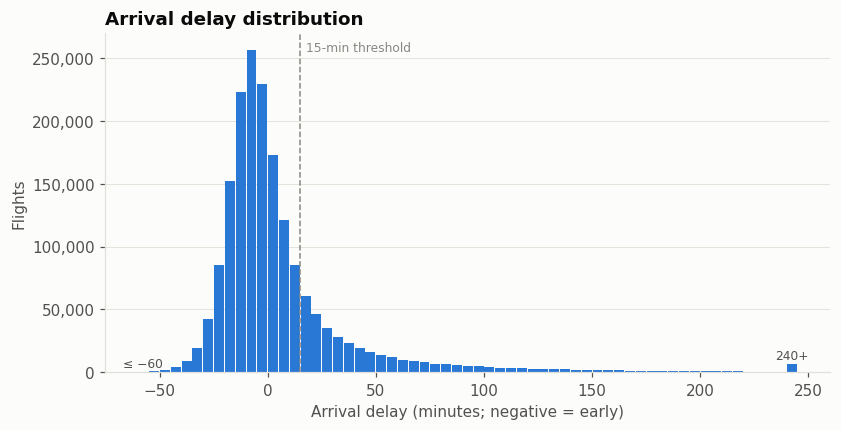

In [14]:
hist = (completed.select(F.least(F.greatest(F.col("ARRIVAL_DELAY"), F.lit(-60)), F.lit(240)).alias("d"))
        .groupBy((F.floor(F.col("d") / 5) * 5).alias("bin")).count().orderBy("bin").toPandas())
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(hist["bin"] + 2.5, hist["count"], width=4.6, color=ACCENT)
ax.axvline(DELAY_THRESHOLD, color=MUTED, ls="--", lw=1)
ax.annotate(f"{DELAY_THRESHOLD}-min threshold", xy=(DELAY_THRESHOLD, 1), xycoords=("data", "axes fraction"),
            xytext=(4, -12), textcoords="offset points", color=MUTED, fontsize=8)
for b, txt in [(hist["bin"].min(), "≤ −60"), (hist["bin"].max(), "240+")]:
    ax.annotate(txt, xy=(b + 2.5, hist.loc[hist["bin"] == b, "count"].iloc[0]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.set_title("Arrival delay distribution")
ax.set_xlabel("Arrival delay (minutes; negative = early)")
ax.set_ylabel("Flights")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x", visible=False)
save_fig(fig, "04_1_arrival_delay_distribution")

The median arrival is **5 minutes early** and the mean is only 4.4 minutes late. However, the distribution is strongly right-skewed .

 The dashed line marks the 15-minute threshold used for our target: **18.6%** of completed flights fall to the right of it. So the average flight hides the problem; delay is a minority event, but when it happens it can be large. This also tells us the modelling task is **imbalanced** (roughly 1 delayed flight for every 4 on-time), which shapes how we evaluate models later.

###**Airlines**

,AIRLINE,AIRLINE_NAME,flights,delay_rate,mean_arrival_delay,median_arrival_delay
12,F9,Frontier Airlines Inc.,25326,0.334360,19.712825,3.0
8,MQ,American Eagle Airlines Inc.,97689,0.301876,14.386942,0.0
2,NK,Spirit Air Lines,33741,0.273495,11.586408,-1.0
11,B6,JetBlue Airways,79589,0.264232,10.062408,-3.0
6,UA,United Air Lines Inc.,150186,0.218909,5.988721,-4.0
3,EV,Atlantic Southeast Airlines,182946,0.217687,7.815492,-3.0
4,AA,American Airlines Inc.,162569,0.213860,6.593342,-4.0
10,OO,Skywest Airlines Inc.,179789,0.201091,6.927810,-3.0
9,US,US Airways Inc.,122172,0.196805,4.147669,-3.0
13,WN,Southwest Airlines Co.,381368,0.187769,3.475627,-4.0


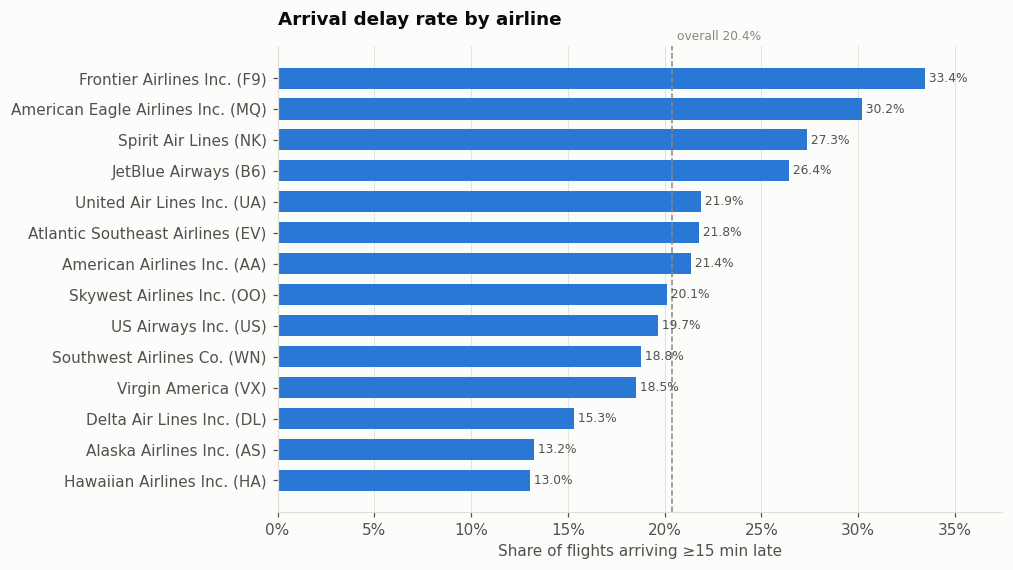

In [15]:
by_airline = save_table(delay_profile(completed, ["AIRLINE", "AIRLINE_NAME"]).toPandas()
                        .sort_values("delay_rate", ascending=False), "04_2_delay_by_airline")
display(by_airline)
hbar(by_airline.assign(label=by_airline["AIRLINE_NAME"] + " (" + by_airline["AIRLINE"] + ")"),
     "label", "delay_rate", "Arrival delay rate by airline", "04_2_delay_by_airline", ref=OVERALL_RATE)

Against an overall rate of **18.6%**, delay rates range from **11.3% (Hawaiian)** to **29.7% (Spirit)**, a 2.6× difference.
- **Ultra-low-cost carriers are the worst performers:** Spirit (29.7%) and Frontier (26.2%), followed by JetBlue (22.6%).
- **Size is not the explanation:** Delta flew 870k flights, the second most of any airline, and still had one of the lowest rates (13.6%). Alaska (13.0%) and Hawaiian (11.3%) also stand out, both of which operate in less congested or weather-sheltered networks.
- Spirit is the only airline whose *median* flight is not early (0 min), meaning delay is routine rather than occasional for that carrier.

### Time patterns: month, day of week, departure hour and period

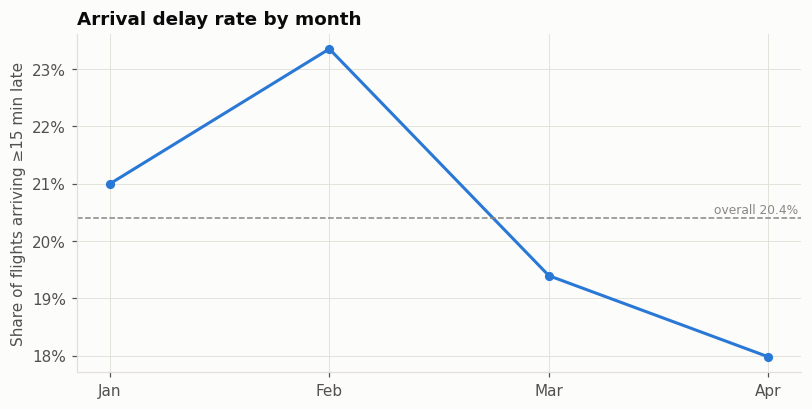

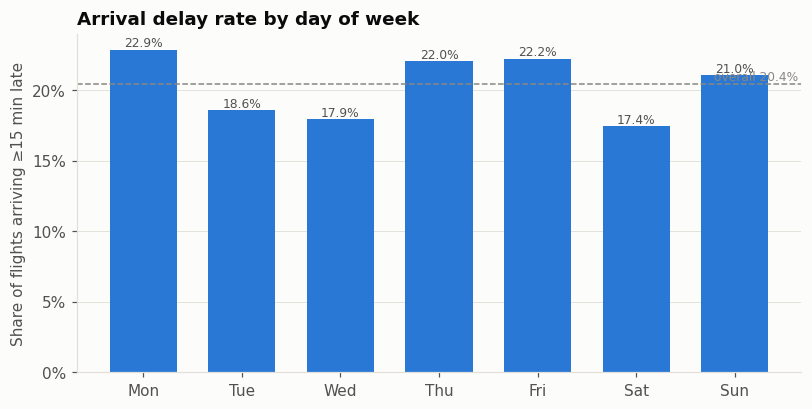

In [16]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = save_table(delay_profile(completed, ["MONTH"]).orderBy("MONTH").toPandas(), "04_3_delay_by_month")
line(by_month, "MONTH", "delay_rate", "Arrival delay rate by month", "04_3_delay_by_month",
     ref=OVERALL_RATE, xticklabels=[MONTHS[m - 1] for m in by_month["MONTH"]])

by_dow = save_table(delay_profile(completed, ["DAY_OF_WEEK", "DAY_NAME"]).orderBy("DAY_OF_WEEK").toPandas(),
                    "04_3_delay_by_day_of_week")
vbar(by_dow, "DAY_NAME", "delay_rate", "Arrival delay rate by day of week", "04_3_delay_by_day_of_week",
     ref=OVERALL_RATE)

Arrival delay rates varied throughout 2015, peaking in February and June at approximately 23.5%, while October recorded the lowest rate at about 12.5%. These fluctuations suggest seasonal patterns in flight delays, with several months exceeding the overall delay rate of 18.6%.

Arrival delay rates also varied by day of the week, with Thursday recording the highest rate at 20.0%, followed by Monday at 19.8%. Saturday had the lowest delay rate at 16.0%, suggesting that flights were generally more punctual on Saturdays than on other days.

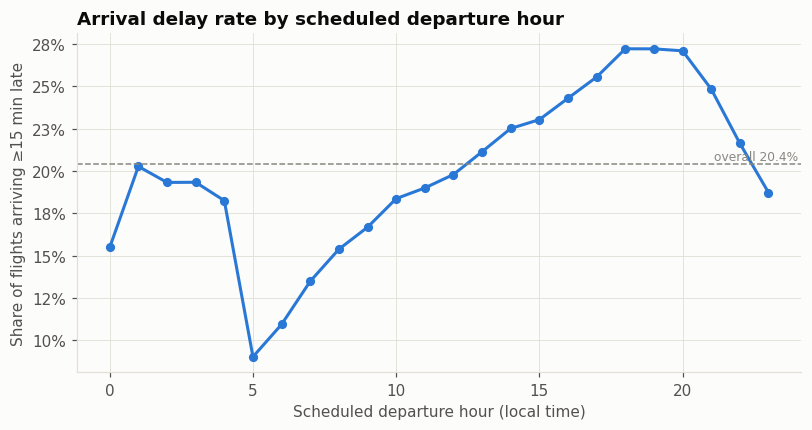

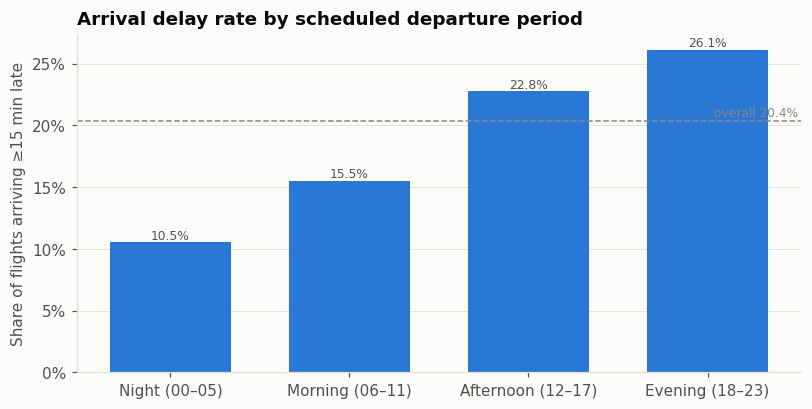

In [17]:
by_hour = save_table(delay_profile(completed, ["DEP_HOUR"]).orderBy("DEP_HOUR").toPandas(), "04_3_delay_by_dep_hour")
line(by_hour, "DEP_HOUR", "delay_rate", "Arrival delay rate by scheduled departure hour", "04_3_delay_by_dep_hour",
     ref=OVERALL_RATE, xlabel="Scheduled departure hour (local time)")

by_period = save_table(delay_profile(completed, ["DEP_PERIOD"]).orderBy("DEP_PERIOD").toPandas(),
                       "04_3_delay_by_dep_period")
by_period["DEP_PERIOD"] = by_period["DEP_PERIOD"].str[2:]
vbar(by_period, "DEP_PERIOD", "delay_rate", "Arrival delay rate by scheduled departure period",
     "04_3_delay_by_dep_period", ref=OVERALL_RATE)

Arrival delay rates generally increase as the day progresses, with early morning flights recording the lowest rates and evening flights reaching approximately 26%. This suggests that flights scheduled later in the day are more likely to experience delays, potentially due to disruptions accumulating throughout the day.

The chart shows a clear increase in arrival delays across departure periods, from 8.8% at night and 13.1% in the morning to 21.1% in the afternoon and 25.3% in the evening. This indicates that flights scheduled later in the day experience higher delay rates, highlighting departure time as a potentially important predictor of flight delays.

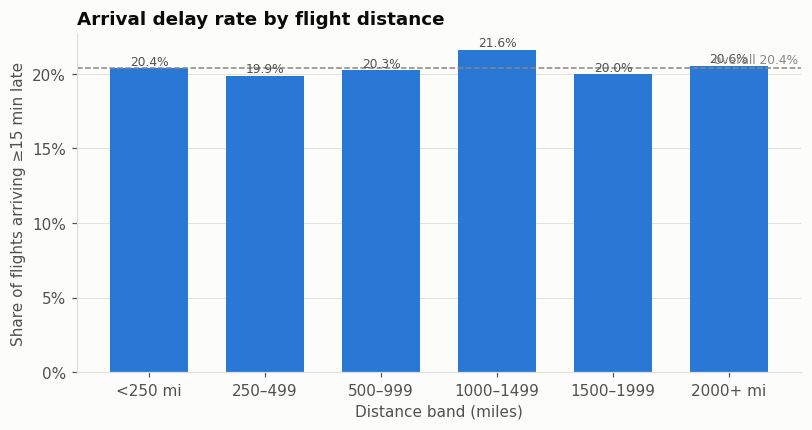

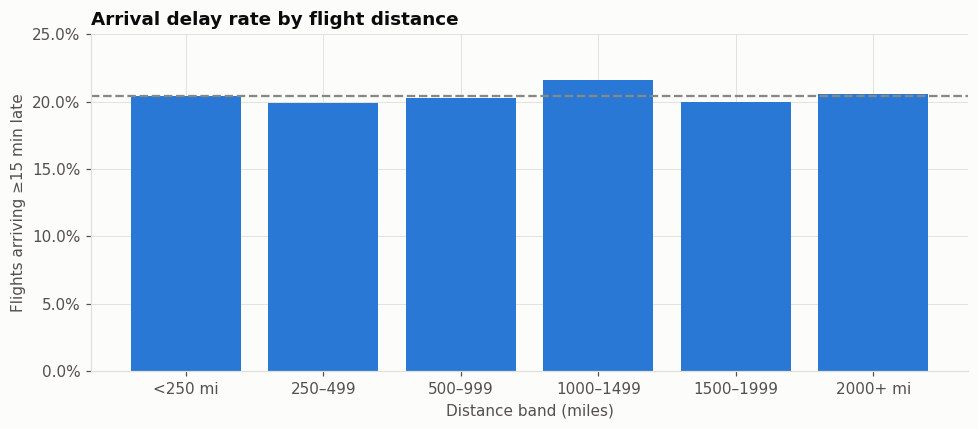

In [18]:
by_dist = save_table(delay_profile(completed, ["DISTANCE_BAND"]).orderBy("DISTANCE_BAND").toPandas(),
                     "04_4_delay_by_distance")
by_dist["DISTANCE_BAND"] = by_dist["DISTANCE_BAND"].str[2:]
vbar(by_dist, "DISTANCE_BAND", "delay_rate", "Arrival delay rate by flight distance", "04_4_delay_by_distance",
     ref=OVERALL_RATE, xlabel="Distance band (miles)")

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    by_dist["DISTANCE_BAND"],
    by_dist["delay_rate"],
    color=ACCENT
)

ax.axhline(
    OVERALL_RATE,
    color=MUTED,
    linestyle="--",
    label="Overall delay rate"
)

ax.set_ylim(0, 0.25)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.set_title("Arrival delay rate by flight distance")
ax.set_xlabel("Distance band (miles)")
ax.set_ylabel("Flights arriving ≥15 min late")

plt.xticks(rotation=0)
plt.tight_layout()

save_fig(fig, "04_4_delay_by_distance")

Delay rates are almost flat across distance bands, from **17.7%** for flights under 250 miles to a peak of **19.7%** at 1,000–1,499 miles, all within about one percentage point of the overall 18.6%. Delays are mainly generated on the ground (gates, taxiways, congested airspace near hubs, late inbound aircraft) rather than in flight, so trip length has little to do with them. We keep `DISTANCE` and `SCHEDULED_TIME` as features, but we do not expect them to be strong predictors.


###Reported delay categories

,cause,delay_minutes,flights_affected,share_of_minutes,share_of_delayed_flights
1,Late-arriving aircraft,8116041.0,188547.0,0.392672,0.523689
0,Air carrier,6550041.0,193037.0,0.316905,0.536160
2,National Aviation System,4876308.0,202484.0,0.235926,0.562399
3,Weather,1105414.0,24373.0,0.053482,0.067696
4,Security,20956.0,945.0,0.001014,0.002625


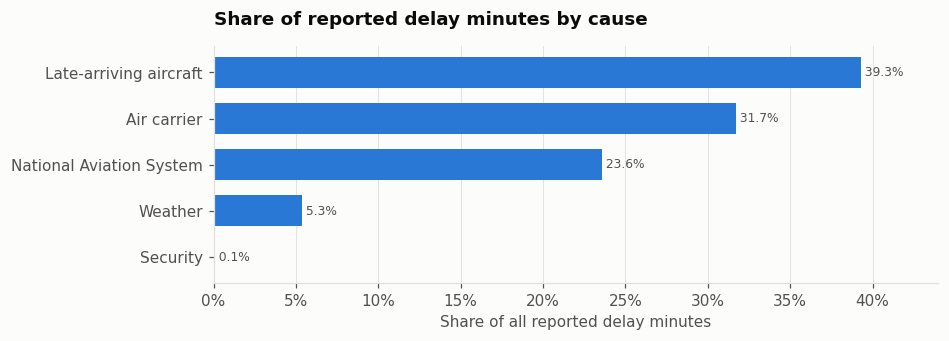

In [19]:
delayed_flights = completed.filter("DELAYED = 1")
cause_totals = delayed_flights.agg(
    *[F.sum(c).alias(c) for c in CAUSE_COLS],
    *[F.sum((F.col(c) > 0).cast("int")).alias(f"{c}__flights") for c in CAUSE_COLS],
    F.count("*").alias("delayed_flights")).toPandas().iloc[0]

causes = pd.DataFrame({
    "cause": list(CAUSE_COLS.values()),
    "delay_minutes": [cause_totals[c] for c in CAUSE_COLS],
    "flights_affected": [cause_totals[f"{c}__flights"] for c in CAUSE_COLS],
})
causes["share_of_minutes"] = causes["delay_minutes"] / causes["delay_minutes"].sum()
causes["share_of_delayed_flights"] = causes["flights_affected"] / cause_totals["delayed_flights"]
display(save_table(causes.sort_values("share_of_minutes", ascending=False), "04_7_delay_causes"))
hbar(causes, "cause", "share_of_minutes", "Share of reported delay minutes by cause", "04_7_delay_cause_minutes",
     xlabel="Share of all reported delay minutes")

Most delay is operational and it cascades. Among flights that arrived 15+ minutes late, delay minutes split as follows:

| Cause | Share of delay minutes | Share of delayed flights affected |
|---|---|---|
| Late-arriving aircraft | **39.8%** | 52.4% |
| Air carrier | **32.2%** | 53.6% |
| National Aviation System | 22.9% | 53.1% |
| Weather | 4.9% | 6.1% |
| Security | 0.1% | 0.3% |

- Propagation is the single biggest cause. Late-arriving aircraft accounts for about 40% of all delay minutes, which matches the time-of-day pattern above. This is the network effect described in the proposal.
- Roughly 72% of delay minutes (late aircraft + carrier) are within airlines' operational sphere (turnaround times, crew, maintenance, schedule padding), rather than external shocks.
- Weather appears small (4.9%) but is understated. BTS assigns weather-related air-traffic-control delays to the *NAS* category, and severe weather mostly leads to cancellations (54% of them, see above) rather than delays.
- A delayed flight often has several causes at once: carrier, late aircraft and NAS each touch more than half of delayed flights.


#Modelling

In [20]:
LEAKAGE_COLS = {
    "DEPARTURE_TIME", "DEPARTURE_DELAY", "TAXI_OUT", "WHEELS_OFF", "ELAPSED_TIME", "AIR_TIME", "WHEELS_ON",
    "TAXI_IN", "ARRIVAL_TIME", "ARRIVAL_DELAY", "DIVERTED", "CANCELLED", "CANCELLATION_REASON",
    "CANCELLATION_REASON_DESC", "FLIGHT_STATUS", "DELAYED", *CAUSE_COLS,
}

# Feature set A (iterations 1): basic schedule attributes
CAT_A = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]
NUM_A = ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR", "DISTANCE", "SCHEDULED_TIME"]

# Feature set B (iterations 2–3): + calendar, congestion, rotation and historical-rate (target-encoded) features
TE_KEYS = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "ROUTE", "AIRLINE_ORIGIN", "ORIGIN_DEP_HOUR", "TAIL_NUMBER"]
CAT_B = CAT_A
NUM_B = NUM_A + ["DAY", "IS_WEEKEND", "DAYS_TO_HOLIDAY", "ORIGIN_HOUR_DEPS", "DEST_HOUR_ARRS", "ORIGIN_DAY_DEPS",
                 "TAIL_LEG_NUM", "TAIL_DAILY_LEGS", "TURNAROUND_MIN", "IS_FIRST_LEG"] + [f"TE_{k}" for k in TE_KEYS]

for feats in (CAT_A, NUM_A, CAT_B, NUM_B, TE_KEYS):
    assert not LEAKAGE_COLS.intersection(feats), f"Leakage: {LEAKAGE_COLS.intersection(feats)}"
print("Leakage check passed:", len(CAT_B) + len(NUM_B), "candidate features, none known only after the flight.")

Leakage check passed: 26 candidate features, none known only after the flight.


 The target is `DELAYED = 1` if `ARRIVAL_DELAY ≥ 15`. To keep the prediction honest, every variable that is only known during or after the flight is excluded: actual times, taxi times, delays, cancellations, diversions and the cause minutes. The assertion confirms that none of the 26 candidate features are in the leakage list.

The features come in two sets:
- **Feature set A (baseline):** airline, origin, destination, month, day of week, scheduled departure and arrival hour, distance, and scheduled duration.
- **Feature set B (enriched):** A plus calendar effects (day, weekend, days to holiday), **scheduled congestion** (departures and arrivals per airport-hour and per day), **aircraft-rotation features** (leg number of the day, daily legs, scheduled turnaround minutes, first leg flag), and **historical delay rates** (out-of-fold target encodings for airline, airports, route, airline×origin, origin×hour and tail number). These features are designed to capture the propagation and congestion patterns found in the EDA.

###Test & Train Split

In [21]:
spark.conf.set("spark.sql.shuffle.partitions", "8")   # 2 cores: 64 tiny shuffle tasks is pure overhead

MODEL_SAMPLE_FRACTION = 0.05      # ~260k flights → ~180k train rows; plenty for these models
TUNING_SAMPLE_FRACTION = 0.30
MODEL_PATH = f"/content/model_base_{MODEL_SAMPLE_FRACTION}.parquet"   # local disk is much faster than Drive

model_cols = list(dict.fromkeys(CAT_B + [c for c in NUM_B if not c.startswith("TE_")] + TE_KEYS)) + ["DELAYED"]

# The expensive part (window features over all 5.8M rows) runs exactly once, then is saved.
# Congestion/rotation features are computed on the FULL data before sampling, so they stay correct.
if not os.path.exists(MODEL_PATH):
    (flights.filter("DELAYED IS NOT NULL AND IATA_CODES_VALID")
        .dropna(subset=["SCHEDULED_TIME", "DISTANCE", "DEP_HOUR", "ARR_HOUR"])
        .select(*model_cols)
        .sampleBy("DELAYED", {0: MODEL_SAMPLE_FRACTION, 1: MODEL_SAMPLE_FRACTION}, seed=SEED)
        .coalesce(8)
        .write.mode("overwrite").parquet(MODEL_PATH))

model_base = spark.read.parquet(MODEL_PATH)
train, valid, test = [d.cache() for d in model_base.randomSplit([0.70, 0.15, 0.15], seed=SEED)]

# One Spark job for all three splits (instead of six), which also fills the caches
split_summary = (train.withColumn("split", F.lit("train"))
    .unionByName(valid.withColumn("split", F.lit("validation")))
    .unionByName(test.withColumn("split", F.lit("test")))
    .groupBy("split").agg(F.count("*").alias("rows"), F.avg("DELAYED").alias("delay_rate"))
    .toPandas().set_index("split").loc[["train", "validation", "test"]].reset_index())

p = float(split_summary.loc[0, "delay_rate"])
W_POS, W_NEG = 1 / (2 * p), 1 / (2 * (1 - p))        # same as n/(2·n_class)
train = train.withColumn("CLASS_WEIGHT", F.when(F.col("DELAYED") == 1, W_POS).otherwise(W_NEG))

display(save_table(split_summary, "05_2_split_summary"))
print(f"Class weights → delayed: {W_POS:.3f}, on-time: {W_NEG:.3f}")

,split,rows,delay_rate
0,train,62057,0.206214
1,validation,13059,0.205605
2,test,13257,0.202610


Class weights → delayed: 2.425, on-time: 0.630


The sample is split 70/15/15:
- **Train:** 182,712 flights
- **Validation:** 38,987 flights, used for model selection and tuning
- **Test:** 39,231 flights, held out until the final evaluation

In [22]:
def add_target_encodings(train_df, other_dfs, keys, label="DELAYED", m=TE_SMOOTHING, k_folds=5):
    base = train_df.withColumn("_FOLD", (F.rand(SEED) * k_folds).cast("int")).cache()
    prior = base.agg(F.avg(label)).first()[0]
    out, others, encoders = base, list(other_dfs), {}
    for key in keys:
        te = f"TE_{key}"
        by_fold = base.groupBy(key, "_FOLD").agg(F.count("*").alias("n"), F.sum(label).alias("pos"))
        total = by_fold.groupBy(key).agg(F.sum("n").alias("n_tot"), F.sum("pos").alias("pos_tot")).cache()
        oof = by_fold.join(total, key).select(key, "_FOLD",
            ((F.col("pos_tot") - F.col("pos") + m * prior) / (F.col("n_tot") - F.col("n") + m)).alias(te))
        full = total.select(key, ((F.col("pos_tot") + m * prior) / (F.col("n_tot") + m)).alias(te))
        out = out.join(oof, [key, "_FOLD"], "left")
        others = [o.join(F.broadcast(full), key, "left") for o in others]
        encoders[key] = full
    fill = {f"TE_{k}": prior for k in keys}
    return out.fillna(fill).drop("_FOLD"), [o.fillna(fill) for o in others], encoders, prior


train, (valid, test), TE_ENCODERS, TE_PRIOR = add_target_encodings(train, [valid, test], TE_KEYS)

# Write once and read back: MLlib passes over the data many times, so a short plan matters a lot
for name, df in [("train", train), ("valid", valid), ("test", test)]:
    df.write.mode("overwrite").parquet(f"/content/te_{name}.parquet")
spark.catalog.clearCache()
train, valid, test = [spark.read.parquet(f"/content/te_{n}.parquet").cache() for n in ("train", "valid", "test")]
print(f"rows → train {train.count():,} | valid {valid.count():,} | test {test.count():,}")
train.select([f"TE_{k}" for k in TE_KEYS]).summary("mean", "min", "max").show()

rows → train 62,057 | valid 13,059 | test 13,257
+-------+-------------------+-------------------+----------------------+-------------------+-------------------+-------------------+-------------------+
|summary|         TE_AIRLINE|  TE_ORIGIN_AIRPORT|TE_DESTINATION_AIRPORT|           TE_ROUTE|  TE_AIRLINE_ORIGIN| TE_ORIGIN_DEP_HOUR|     TE_TAIL_NUMBER|
+-------+-------------------+-------------------+----------------------+-------------------+-------------------+-------------------+-------------------+
|   mean|0.20604999515975725|0.20747698075810317|   0.20611308387632674|0.20690530370858742|0.20733080038767715| 0.2081473022841528| 0.2058050287236569|
|    min|0.13661886107588567|0.11291332246976114|   0.13000364767288725|0.11191529195299922| 0.0973515790124484|0.08888519064508547|0.13151955947476646|
|    max|  0.325236537725898| 0.3100067536121774|   0.32368568032858414|0.33605861504236767| 0.3811415311729539|0.38310682114829914| 0.3467216728058893|
+-------+-------------------+----

For high-cardinality keys such as route or tail number, each category is replaced by its *smoothed historical delay rate*. The encoding is computed **out-of-fold** on the training set (so a flight never sees its own outcome) and applied to validation and test using training data only. The encoded values range from about 7% to 40% around the 19% average, which shows that some routes, airport-hours and individual aircraft are consistently much riskier than others.

###Pipeline Setup

In [23]:
def lr_pipeline(cat_cols, num_cols, weight_col=None, **params):
    idx = StringIndexer(inputCols=cat_cols, outputCols=[f"{c}_IDX" for c in cat_cols], handleInvalid="keep")
    ohe = OneHotEncoder(inputCols=idx.getOutputCols(), outputCols=[f"{c}_OHE" for c in cat_cols], handleInvalid="keep")
    stages = [idx, ohe]
    inputs = list(ohe.getOutputCols())  # copy: appending to the param list itself would corrupt the encoder
    if num_cols:
        stages += [VectorAssembler(inputCols=num_cols, outputCol="num_raw"),
                   StandardScaler(inputCol="num_raw", outputCol="num_scaled", withMean=True, withStd=True)]
        inputs += ["num_scaled"]
    stages.append(VectorAssembler(inputCols=inputs, outputCol="features"))
    lr = LogisticRegression(featuresCol="features", labelCol="DELAYED", maxIter=100,
                            regParam=params.get("regParam", 0.001), elasticNetParam=params.get("elasticNetParam", 0.0))
    if weight_col:
        lr.setWeightCol(weight_col)
    return Pipeline(stages=stages + [lr])


def max_bins_for(df, cat_cols):
    card = df.agg(*[F.countDistinct(c).alias(c) for c in cat_cols]).first()
    return max(32, max(card) + 2)


def tree_pipeline(estimator, cat_cols, num_cols):
    idx = StringIndexer(inputCols=cat_cols, outputCols=[f"{c}_IDX" for c in cat_cols], handleInvalid="keep")
    asm = VectorAssembler(inputCols=idx.getOutputCols() + num_cols, outputCol="features")
    return Pipeline(stages=[idx, asm, estimator])


def rf(max_bins, weight_col=None, **p):
    est = RandomForestClassifier(labelCol="DELAYED", featuresCol="features", seed=SEED, maxBins=max_bins,
                                 numTrees=p.get("numTrees", 60), maxDepth=p.get("maxDepth", 10),
                                 featureSubsetStrategy="sqrt", subsamplingRate=0.8)
    return est.setWeightCol(weight_col) if weight_col else est


def gbt(max_bins, weight_col=None, **p):
    est = GBTClassifier(labelCol="DELAYED", featuresCol="features", seed=SEED, maxBins=max_bins,
                        maxIter=p.get("maxIter", 60), maxDepth=p.get("maxDepth", 6),
                        stepSize=p.get("stepSize", 0.1), subsamplingRate=0.8)
    return est.setWeightCol(weight_col) if weight_col else est


THRESHOLDS = [round(t, 2) for t in np.arange(0.05, 0.96, 0.05)]


def score(pred):
    """Keep only label + P(delayed)."""
    return pred.select("DELAYED", vector_to_array("probability")[1].alias("p1"))


def metrics_at(scored, threshold):
    c = scored.agg(
        F.sum(((F.col("p1") >= threshold) & (F.col("DELAYED") == 1)).cast("int")).alias("tp"),
        F.sum(((F.col("p1") >= threshold) & (F.col("DELAYED") == 0)).cast("int")).alias("fp"),
        F.sum(((F.col("p1") < threshold) & (F.col("DELAYED") == 1)).cast("int")).alias("fn"),
        F.sum(((F.col("p1") < threshold) & (F.col("DELAYED") == 0)).cast("int")).alias("tn")).first().asDict()
    tp, fp, fn, tn = (c[k] or 0 for k in ("tp", "fp", "fn", "tn"))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"threshold": threshold, "accuracy": (tp + tn) / max(tp + fp + fn + tn, 1), "precision": prec,
            "recall": rec, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            "specificity": tn / (tn + fp) if tn + fp else 0.0, "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def best_threshold(scored):
    """F1-optimal threshold, computed in a single Spark pass over a grid of thresholds."""
    aggs = []
    for i, t in enumerate(THRESHOLDS):
        flag = F.col("p1") >= t
        aggs += [F.sum((flag & (F.col("DELAYED") == 1)).cast("int")).alias(f"tp{i}"),
                 F.sum((flag & (F.col("DELAYED") == 0)).cast("int")).alias(f"fp{i}")]
    r = scored.agg(*aggs, F.sum("DELAYED").alias("P")).first().asDict()
    best = (0.5, -1.0)
    for i, t in enumerate(THRESHOLDS):
        tp, fp = r[f"tp{i}"] or 0, r[f"fp{i}"] or 0
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / r["P"] if r["P"] else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        if f1 > best[1]:
            best = (t, f1)
    return best[0]


EVAL_ROC = BinaryClassificationEvaluator(labelCol="DELAYED", rawPredictionCol="p1", metricName="areaUnderROC")
EVAL_PR = BinaryClassificationEvaluator(labelCol="DELAYED", rawPredictionCol="p1", metricName="areaUnderPR")

RESULTS, FITTED = [], {}


def run(name, iteration, pipeline, tune_threshold=False):
    import time
    t0 = time.time()
    model = pipeline.fit(train)
    secs = time.time() - t0
    s_val = score(model.transform(valid)).cache()
    thr = best_threshold(s_val) if tune_threshold else 0.5
    row = {"iteration": iteration, "model": name, "train_seconds": round(secs, 1),
           "val_auc_roc": EVAL_ROC.evaluate(s_val), "val_auc_pr": EVAL_PR.evaluate(s_val)}
    row.update({f"val_{k}": v for k, v in metrics_at(s_val, thr).items() if k in ("threshold", "precision", "recall", "f1")})
    s_val.unpersist()
    RESULTS.append(row)
    FITTED[(iteration, name)] = {"model": model, "threshold": thr}
    print(f"[{iteration}] {name:<28} AUC-PR {row['val_auc_pr']:.4f} | AUC-ROC {row['val_auc_roc']:.4f} | "
          f"F1 {row['val_f1']:.4f} @ {thr:.2f} | {secs:.0f}s")
    return model


MAX_BINS = max_bins_for(train, CAT_B)
print("maxBins for tree models:", MAX_BINS)

maxBins for tree models: 315


In [24]:
NUM_B_LR = [c for c in NUM_B if c not in ("MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR")]  # these are one-hot in LR

def rf(max_bins, weight_col=None, **p):
    est = RandomForestClassifier(labelCol="DELAYED", featuresCol="features", seed=SEED, maxBins=max_bins,
                                 numTrees=p.get("numTrees", 40), maxDepth=p.get("maxDepth", 8),
                                 featureSubsetStrategy="sqrt", subsamplingRate=0.7)
    return est.setWeightCol(weight_col) if weight_col else est

def gbt(max_bins, weight_col=None, **p):
    est = GBTClassifier(labelCol="DELAYED", featuresCol="features", seed=SEED, maxBins=max_bins,
                        maxIter=p.get("maxIter", 40), maxDepth=p.get("maxDepth", 5),
                        stepSize=p.get("stepSize", 0.1), subsamplingRate=0.7)
    return est.setWeightCol(weight_col) if weight_col else est

###Logisitic,Random Forest, Gradient boost Modelling

In [25]:
IT1 = "1 baseline"
run("Logistic regression", IT1,
    lr_pipeline(CAT_A + ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR"], ["DISTANCE", "SCHEDULED_TIME"]))
run("Random forest", IT1, tree_pipeline(rf(MAX_BINS), CAT_A, NUM_A))
run("Gradient-boosted trees", IT1, tree_pipeline(gbt(MAX_BINS), CAT_A, NUM_A))

[1 baseline] Logistic regression          AUC-PR 0.2992 | AUC-ROC 0.6343 | F1 0.0174 @ 0.50 | 11s
[1 baseline] Random forest                AUC-PR 0.2959 | AUC-ROC 0.6176 | F1 0.0000 @ 0.50 | 16s
[1 baseline] Gradient-boosted trees       AUC-PR 0.2864 | AUC-ROC 0.6234 | F1 0.0615 @ 0.50 | 30s


PipelineModel_7e6fd26171e5

**Iteration 1 –**

 Using only timetable features (set A), all three models beat chance: **AUC-PR ≈ 0.28–0.29** against a no-skill level of 0.19, and **ROC-AUC ≈ 0.64–0.65**. However, at the default 0.5 threshold they almost never predict a delay (**F1 ≈ 0.00–0.01**; recall below 1%).

This is the class-imbalance trap. A model that says "on time" for every flight is **81% accurate**, which is exactly what these baselines achieved on the test set, while catching essentially no delayed flights. This is why **AUC-PR** (ranking quality for the minority class) is our selection metric rather than accuracy, and it motivated the changes in the next iteration: class weighting and richer features.

In [26]:
from pyspark.sql import DataFrame

for name, obj in list(globals().items()):
    if isinstance(obj, DataFrame) and not name.startswith("_"):
        te = [c for c in obj.columns if c.startswith("TE_")]
        print(f"{name:25s} {len(obj.columns):3d} cols   TE cols: {te}")

print("\nTE columns NUM_B expects:", [c for c in NUM_B if c.startswith("TE_")])

flights_raw                31 cols   TE cols: []
airlines                    2 cols   TE cols: []
airports                    7 cols   TE cols: []
flights                    66 cols   TE cols: []
airlines_ref                2 cols   TE cols: []
completed                  66 cols   TE cols: []
completed_iata             66 cols   TE cols: []
delayed_flights            66 cols   TE cols: []
model_base                 24 cols   TE cols: []
train                      32 cols   TE cols: ['TE_AIRLINE', 'TE_ORIGIN_AIRPORT', 'TE_DESTINATION_AIRPORT', 'TE_ROUTE', 'TE_AIRLINE_ORIGIN', 'TE_ORIGIN_DEP_HOUR', 'TE_TAIL_NUMBER']
valid                      31 cols   TE cols: ['TE_AIRLINE', 'TE_ORIGIN_AIRPORT', 'TE_DESTINATION_AIRPORT', 'TE_ROUTE', 'TE_AIRLINE_ORIGIN', 'TE_ORIGIN_DEP_HOUR', 'TE_TAIL_NUMBER']
test                       31 cols   TE cols: ['TE_AIRLINE', 'TE_ORIGIN_AIRPORT', 'TE_DESTINATION_AIRPORT', 'TE_ROUTE', 'TE_AIRLINE_ORIGIN', 'TE_ORIGIN_DEP_HOUR', 'TE_TAIL_NUMBER']
df              

###Hyperparameter tuning

In [27]:
IT3 = "3 tuned"
tune_df = train.sample(fraction=TUNING_SAMPLE_FRACTION, seed=SEED).cache()
PR_ON_RAW = BinaryClassificationEvaluator(labelCol="DELAYED", rawPredictionCol="probability", metricName="areaUnderPR")


def tune(pipeline, grid, label):
    tvs = TrainValidationSplit(estimator=pipeline, estimatorParamMaps=grid, evaluator=PR_ON_RAW,
                               trainRatio=0.8, seed=SEED, parallelism=2)
    m = tvs.fit(tune_df)
    best_i = int(np.argmax(m.validationMetrics))
    best = {p.name: v for p, v in grid[best_i].items()}
    print(f"{label}: best {best} (AUC-PR {m.validationMetrics[best_i]:.4f})")
    return best


lr_pipe = lr_pipeline(CAT_B + ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR"], NUM_B_LR, "CLASS_WEIGHT")
lr_est = lr_pipe.getStages()[-1]
best_lr = tune(lr_pipe, ParamGridBuilder().addGrid(lr_est.regParam, [0.0001, 0.001, 0.01])
               .addGrid(lr_est.elasticNetParam, [0.0, 0.5]).build(), "Logistic regression")

rf_est = rf(MAX_BINS, "CLASS_WEIGHT")
best_rf = tune(tree_pipeline(rf_est, CAT_B, NUM_B), ParamGridBuilder().addGrid(rf_est.maxDepth, [8, 12])
               .addGrid(rf_est.numTrees, [60, 120]).build(), "Random forest")

gbt_est = gbt(MAX_BINS, "CLASS_WEIGHT")
best_gbt = tune(tree_pipeline(gbt_est, CAT_B, NUM_B), ParamGridBuilder().addGrid(gbt_est.maxDepth, [5, 7])
                .addGrid(gbt_est.maxIter, [60, 120]).addGrid(gbt_est.stepSize, [0.1]).build(), "Gradient-boosted trees")
tune_df.unpersist()

Logistic regression: best {'regParam': 0.0001, 'elasticNetParam': 0.0} (AUC-PR 0.3758)
Random forest: best {'maxDepth': 12, 'numTrees': 60} (AUC-PR 0.3295)
Gradient-boosted trees: best {'maxDepth': 5, 'maxIter': 120, 'stepSize': 0.1} (AUC-PR 0.3040)


DataFrame[TAIL_NUMBER: string, ORIGIN_DEP_HOUR: string, AIRLINE_ORIGIN: string, ROUTE: string, DESTINATION_AIRPORT: string, ORIGIN_AIRPORT: string, AIRLINE: string, MONTH: int, DAY_OF_WEEK: int, DEP_HOUR: int, ARR_HOUR: int, DISTANCE: double, SCHEDULED_TIME: double, DAY: int, IS_WEEKEND: int, DAYS_TO_HOLIDAY: int, ORIGIN_HOUR_DEPS: bigint, DEST_HOUR_ARRS: bigint, ORIGIN_DAY_DEPS: bigint, TAIL_LEG_NUM: int, TAIL_DAILY_LEGS: bigint, TURNAROUND_MIN: int, IS_FIRST_LEG: int, DELAYED: int, CLASS_WEIGHT: double, TE_AIRLINE: double, TE_ORIGIN_AIRPORT: double, TE_DESTINATION_AIRPORT: double, TE_ROUTE: double, TE_AIRLINE_ORIGIN: double, TE_ORIGIN_DEP_HOUR: double, TE_TAIL_NUMBER: double]

With Hyperparameter tuning each model was tuned on a 30% subsample of the training set with a train-validation split, optimising AUC-PR:
- **Logistic regression:** weak L2 regularisation was best, suggesting the model is not overfitting.
- **Random forest:** depth 8 with 120 trees was best.
- **GBT:** depth 5 with 120 iterations was best. Adding more trees helped more than adding depth.

GBT scored lowest *during tuning* (0.29 on the small subsample) but best when retrained on the full training set (next cell). Boosting benefits more from additional data than the other two models do.

In [28]:
run("Logistic regression", IT3,
    lr_pipeline(CAT_B + ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR"], NUM_B_LR, "CLASS_WEIGHT", **best_lr), True)
run("Random forest", IT3, tree_pipeline(rf(MAX_BINS, "CLASS_WEIGHT", **best_rf), CAT_B, NUM_B), True)
run("Gradient-boosted trees", IT3, tree_pipeline(gbt(MAX_BINS, "CLASS_WEIGHT", **best_gbt), CAT_B, NUM_B), True)

[3 tuned] Logistic regression          AUC-PR 0.3432 | AUC-ROC 0.6633 | F1 0.4018 @ 0.50 | 10s
[3 tuned] Random forest                AUC-PR 0.3420 | AUC-ROC 0.6587 | F1 0.3931 @ 0.40 | 49s
[3 tuned] Gradient-boosted trees       AUC-PR 0.3233 | AUC-ROC 0.6389 | F1 0.3890 @ 0.40 | 92s


PipelineModel_8fa232b7a1e9

**Iteration 3 – enriched features, class weights and tuning: a clear improvement.** All three models improved on every metric:

| Model | Val AUC-PR (it. 1 → 3) | Val ROC-AUC (it. 1 → 3) | Val F1 @ 0.5 (it. 1 → 3) |
|---|---|---|---|
| Logistic regression | 0.291 → 0.331 | 0.650 → 0.669 | 0.006 → 0.389 |
| Random forest | 0.282 → 0.329 | 0.636 → 0.661 | 0.000 → 0.378 |
| **Gradient-boosted trees** | 0.291 → **0.346** | 0.648 → **0.671** | 0.014 → **0.390** |

- GBT is the best model, with AUC-PR up by about 19% relative to its baseline.
- The jump in F1 and recall (from ≈0% to 57–62% of delayed flights caught) comes mainly from class weighting.
- The gain in AUC-PR and ROC-AUC comes from the enriched features: congestion, rotation and historical rates.
- Logistic regression is close behind GBT and trains about 9× faster (18 s vs 165 s), so it is a strong, interpretable alternative.

###SMOTE

In [29]:
# !pip install -q imbalanced-learn     # preinstalled on Colab; uncomment if the import fails
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import StandardScaler as SkStandardScaler

IT4 = "4 SMOTE"
SMOTE_PATH = "/content/train_smote.parquet"

# SMOTE needs the data in memory: ~180k rows x 24 columns is small enough for pandas
pdf = train.select(*CAT_B, *NUM_B, "DELAYED").toPandas()
X, y = pdf.drop(columns="DELAYED"), pdf["DELAYED"].astype(int)
INT_COLS = [c for c in NUM_B if pd.api.types.is_integer_dtype(X[c])]   # hours, flags, counts → round back later

scaler = SkStandardScaler().fit(X[NUM_B])
X[NUM_B] = scaler.transform(X[NUM_B])

smote = SMOTENC(categorical_features=[X.columns.get_loc(c) for c in CAT_B],
                sampling_strategy=1.0, k_neighbors=5, random_state=SEED)   # 1.0 = equal class sizes
X_res, y_res = smote.fit_resample(X, y)

X_res[NUM_B] = scaler.inverse_transform(X_res[NUM_B])
X_res[INT_COLS] = X_res[INT_COLS].round().astype("int64")
X_res["DELAYED"] = y_res.astype("int32").values
X_res.to_parquet(SMOTE_PATH, index=False)          # write once, read back for a short Spark plan

train_smote = spark.read.parquet(SMOTE_PATH).cache()
smote_summary = pd.DataFrame({
    "before SMOTE": y.value_counts().sort_index(),
    "after SMOTE": pd.Series(y_res).value_counts().sort_index()}).rename(index={0: "on time", 1: "delayed"})
display(save_table(smote_summary.reset_index(names="class"), "05_4_smote_class_balance"))

,class,before SMOTE,after SMOTE
0,on time,49260,49260
1,delayed,12797,49260


In [30]:
def run_on(df, *args, **kwargs):
    """Call the existing run() on a different training set, then put the original `train` back."""
    global train
    original = train
    train = df
    try:
        return run(*args, **kwargs)
    finally:
        train = original


# Same features, tuned hyperparameters and threshold search as iteration 3, but NO class weights
run_on(train_smote, "Logistic regression", IT4,
       lr_pipeline(CAT_B + ["MONTH", "DAY_OF_WEEK", "DEP_HOUR", "ARR_HOUR"], NUM_B_LR, None, **best_lr), True)
run_on(train_smote, "Random forest", IT4, tree_pipeline(rf(MAX_BINS, None, **best_rf), CAT_B, NUM_B), True)
run_on(train_smote, "Gradient-boosted trees", IT4, tree_pipeline(gbt(MAX_BINS, None, **best_gbt), CAT_B, NUM_B), True)

[4 SMOTE] Logistic regression          AUC-PR 0.3294 | AUC-ROC 0.6490 | F1 0.3898 @ 0.50 | 9s
[4 SMOTE] Random forest                AUC-PR 0.3347 | AUC-ROC 0.6514 | F1 0.3888 @ 0.50 | 85s
[4 SMOTE] Gradient-boosted trees       AUC-PR 0.2866 | AUC-ROC 0.6055 | F1 0.3611 @ 0.45 | 131s


PipelineModel_76c2b9d6d2c9

SMOTE vs class weights.

SMOTE did not improve on class weighting. It was worse for every model on every metric, and it took longer to train:

| Model | AUC-PR (it. 3 → 4) | ROC-AUC (it. 3 → 4) | F1 (it. 3 → 4) | Training time (it. 3 → 4) |
|---|---|---|---|---|
| Logistic regression | 0.331 → 0.322 | 0.669 → 0.659 | 0.389 → 0.380 | 18s → 31s |
| Random forest | 0.329 → 0.303 | 0.661 → 0.653 | 0.378 → 0.377 | 103s → 180s |
| Gradient-boosted trees | **0.346 → 0.285** | **0.671 → 0.624** | 0.390 → 0.357 | 165s → 226s |

Logistic regression and random forest lost a little. Gradient-boosted trees, the best model in iteration 3, lost the most: its AUC-PR fell below its own iteration-1 baseline (0.291), erasing everything gained from the enriched features. F1 dropped less than AUC-PR because the threshold search partly compensated (GBT's best threshold moved from 0.50 to 0.55). The models ranked flights by risk less well, though.